# Lecture Notes: Implicit Differentiation
*Stewart, **Calculus**, 9th ed., §3.5*

**Learning objectives.** By the end of this lecture you should be able to:
1. Distinguish a function given **explicitly**, $y = f(x)$, from one defined **implicitly** by an equation in $x$ and $y$.
2. Find $\dfrac{dy}{dx}$ by **implicit differentiation**, treating $y$ as a function of $x$ and using the Chain Rule.
3. Find tangent lines, and points with horizontal or vertical tangents, on curves such as circles and the folium of Descartes.
4. Find second derivatives implicitly and simplify them using the original equation.
5. Derive the derivatives of the **inverse trigonometric functions**.
6. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, y = sp.symbols("x y")

## 1. Explicit and implicit functions

So far every function has been given **explicitly**: $y$ is written as a formula in $x$, such as
$$y = \sqrt{x^3 + 1} \qquad\text{or}\qquad y = x\sin x.$$
Some curves are instead described by a **relation** between $x$ and $y$:
$$x^2 + y^2 = 25 \qquad\qquad x^3 + y^3 = 6xy.$$
Such an equation defines $y$ **implicitly** as one or more functions of $x$. The circle $x^2 + y^2 = 25$ can be solved for $y$, giving two functions
$$f(x) = \sqrt{25 - x^2}, \qquad g(x) = -\sqrt{25 - x^2},$$
the upper and lower semicircles. The **folium of Descartes** $x^3 + y^3 = 6xy$ can also be solved for $y$ in principle, but the formulas from the cubic formula are very messy. For equations like $y^5 + 3x^2y^2 + 5x^4 = 12$ there is no formula at all.

We don't need to solve for $y$. **Implicit differentiation** finds $\dfrac{dy}{dx}$ directly from the equation.

**The method.**
1. Differentiate **both sides** of the equation with respect to $x$, treating $y$ as a function $y(x)$.
2. Each time you differentiate an expression in $y$, apply the **Chain Rule**: $\dfrac{d}{dx}\,h(y) = h'(y)\,\dfrac{dy}{dx}$. For example, $\dfrac{d}{dx}\left(y^2\right) = 2y\,\dfrac{dy}{dx}$.
3. Solve the resulting equation for $\dfrac{dy}{dx}$. It is linear in $\dfrac{dy}{dx}$, so this is just algebra.

The answer usually involves **both** $x$ and $y$. That is expected: at a given $x$ there may be several points on the curve, each with its own slope.

SymPy can follow the same steps if we make $y$ a function of $x$:

In [2]:
Y = sp.Function("y")(x)
lhs = sp.diff(x**2 + Y**2, x)
display(Math(rf"\frac{{d}}{{dx}}\left(x^2 + y^2\right) = {sp.latex(lhs)}"))
display(Math(rf"\frac{{dy}}{{dx}} = {sp.latex(sp.solve(sp.Eq(lhs, 0), Y.diff(x))[0])}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

SymPy also has `idiff`, which does all three steps at once. The helper below compares a derivative found by hand with `idiff`. An implicit derivative can often be written in several forms that agree only **on the curve**, so if the two answers are not identical, the helper also checks whether their difference vanishes whenever the equation holds.

In [3]:
def check(eq, by_hand, order=1):
    """Display d^n y/dx^n = by_hand on the curve eq and confirm it agrees with SymPy."""
    F = eq.lhs - eq.rhs
    diff = sp.numer(sp.together(sp.idiff(F, y, x, order) - by_hand))
    ok = sp.simplify(diff) == 0
    if not ok and F.is_polynomial(x, y):
        ok = sp.rem(sp.expand(diff), F, y) == 0  # difference is a multiple of F, so it is 0 on the curve
    d = r"\frac{dy}{dx}" if order == 1 else rf"\frac{{d^{order}y}}{{dx^{order}}}"
    display(Math(rf"{sp.latex(eq)}: \qquad {d} = {sp.latex(by_hand)}"))
    print("Agrees with SymPy:", ok)

## 2. Tangent lines to implicit curves

**Example 1.** (a) Find $\dfrac{dy}{dx}$ if $x^2 + y^2 = 25$. (b) Find the tangent line to the circle at $(3, 4)$.

*(a) By hand.* Differentiate both sides with respect to $x$:
$$\frac{d}{dx}\left(x^2\right) + \frac{d}{dx}\left(y^2\right) = \frac{d}{dx}(25)
\quad\Longrightarrow\quad
2x + 2y\,\frac{dy}{dx} = 0
\quad\Longrightarrow\quad
\frac{dy}{dx} = -\frac{x}{y}.$$

*(b)* At $(3, 4)$ the slope is $-\dfrac34$, so the tangent line is
$$y - 4 = -\frac34(x - 3) \qquad\text{or}\qquad 3x + 4y = 25.$$

*Explicit check.* The point $(3, 4)$ is on the upper semicircle $y = \sqrt{25 - x^2}$, whose derivative is
$$\frac{dy}{dx} = \frac{-x}{\sqrt{25-x^2}} = -\frac{x}{y},$$
the same answer. Implicit differentiation gives one formula that works on **both** semicircles.

**Geometric check.** $-\dfrac{x}{y}$ is the negative reciprocal of the slope $\dfrac{y}{x}$ of the radius, so the tangent is perpendicular to the radius, as we expect from geometry.

In [4]:
circle = sp.Eq(x**2 + y**2, 25)
check(circle, -x / y)

explicit = sp.diff(sp.sqrt(25 - x**2), x)
print("Explicit slope at x = 3:", explicit.subs(x, 3))

<IPython.core.display.Math object>

Agrees with SymPy: True
Explicit slope at x = 3: -3/4


**Example 2.** The folium of Descartes $x^3 + y^3 = 6xy$.
(a) Find $y'$. (b) Find the tangent line at $(3, 3)$. (c) At what point in the first quadrant is the tangent line horizontal?

*(a) By hand.* The right side is a product, so it needs the Product Rule:
$$3x^2 + 3y^2 y' = 6y + 6x y'.$$
Collect the $y'$ terms on one side and divide by $3$:
$$y^2 y' - 2x y' = 2y - x^2
\quad\Longrightarrow\quad
y' = \frac{2y - x^2}{y^2 - 2x}.$$

*(b)* At $(3, 3)$, $y' = \dfrac{6 - 9}{9 - 6} = -1$. The tangent line is $y - 3 = -(x - 3)$, i.e. $x + y = 6$. Since the curve is symmetric about $y = x$, a slope of $-1$ at $(3,3)$ is what we would expect.

*(c)* The tangent is horizontal when $y' = 0$, i.e. when $2y - x^2 = 0$ (and $y^2 - 2x \ne 0$). Substitute $y = \tfrac12 x^2$ into the curve's equation:
$$x^3 + \tfrac18 x^6 = 6x\left(\tfrac12 x^2\right) = 3x^3
\quad\Longrightarrow\quad
x^6 = 16x^3
\quad\Longrightarrow\quad
x^3(x^3 - 16) = 0.$$
In the first quadrant $x \ne 0$, so $x = 16^{1/3} = 2^{4/3} \approx 2.52$ and $y = \tfrac12 x^2 = 2^{5/3} \approx 3.17$.

In [5]:
folium = sp.Eq(x**3 + y**3, 6*x*y)
yp = (2*y - x**2) / (y**2 - 2*x)
check(folium, yp)
print("Slope at (3, 3):", yp.subs({x: 3, y: 3}))

# horizontal tangent: numerator of y' = 0 together with the curve
sols = sp.solve([2*y - x**2, folium.lhs - folium.rhs], [x, y], dict=True)
first_quadrant = [s for s in sols if s[x].is_positive and s[y].is_positive]
for s in first_quadrant:
    display(Math(rf"(x, y) = \left({sp.latex(sp.nsimplify(s[x]))},\ {sp.latex(sp.nsimplify(s[y]))}\right) \approx ({float(s[x]):.3f},\ {float(s[y]):.3f})"))

<IPython.core.display.Math object>

Agrees with SymPy: True
Slope at (3, 3): -1


<IPython.core.display.Math object>

The plot draws both curves as level sets of $F(x, y) = 0$, using a contour plot, so we never solve for $y$. It also shows the tangent lines found above.

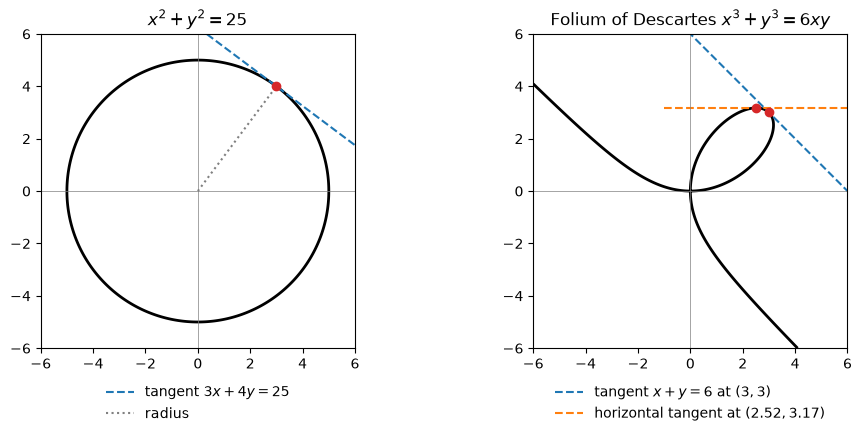

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
X, Yg = np.meshgrid(np.linspace(-6, 6, 600), np.linspace(-6, 6, 600))

ax = axes[0]
ax.contour(X, Yg, X**2 + Yg**2 - 25, levels=[0], colors="k", linewidths=2)
xs = np.linspace(-1, 7, 2)
ax.plot(xs, (25 - 3 * xs) / 4, "--", label=r"tangent $3x + 4y = 25$")
ax.plot([0, 3], [0, 4], ":", color="gray", label="radius")
ax.plot(3, 4, "o", color="C3")
ax.set_title(r"$x^2 + y^2 = 25$")

ax = axes[1]
ax.contour(X, Yg, X**3 + Yg**3 - 6 * X * Yg, levels=[0], colors="k", linewidths=2)
xs = np.linspace(-1, 7, 2)
ax.plot(xs, 6 - xs, "--", label=r"tangent $x + y = 6$ at $(3,3)$")
x0, y0 = 2**(4/3), 2**(5/3)
ax.plot(xs, np.full_like(xs, y0), "--", label=rf"horizontal tangent at $({x0:.2f}, {y0:.2f})$")
ax.plot([3, x0], [3, y0], "o", color="C3")
ax.set_title(r"Folium of Descartes $x^3 + y^3 = 6xy$")

for ax in axes:
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()
plt.show()

**Example 3.** Find $y'$ if $\sin(x + y) = y^2\cos x$.

*By hand.* Chain Rule on the left, Product Rule and Chain Rule on the right:
$$\cos(x + y)\,(1 + y') = 2y\,y'\cos x - y^2\sin x.$$
Collect the $y'$ terms:
$$\cos(x+y) + y^2\sin x = 2y\cos x\,y' - \cos(x+y)\,y'
\quad\Longrightarrow\quad
y' = \frac{y^2\sin x + \cos(x+y)}{2y\cos x - \cos(x+y)}.$$
Remember that $\dfrac{d}{dx}(x + y) = 1 + y'$, **not** $1$.

In [7]:
check(sp.Eq(sp.sin(x + y), y**2 * sp.cos(x)),
      (y**2 * sp.sin(x) + sp.cos(x + y)) / (2*y * sp.cos(x) - sp.cos(x + y)))

<IPython.core.display.Math object>

Agrees with SymPy: True


## 3. Second derivatives

To find $y''$, differentiate the formula for $y'$ implicitly again, remembering that $y$ is still a function of $x$. Then substitute the formula for $y'$, and use the original equation to simplify.

**Example 4.** Find $y''$ if $x^4 + y^4 = 16$.

*By hand.* First,
$$4x^3 + 4y^3 y' = 0 \quad\Longrightarrow\quad y' = -\frac{x^3}{y^3}.$$
Now use the Quotient Rule, with $y$ a function of $x$:
$$y'' = -\frac{y^3\cdot 3x^2 - x^3\cdot 3y^2\,y'}{y^6}.$$
Substitute $y' = -x^3/y^3$ and multiply the top and bottom by $y$:
$$y'' = -\frac{3x^2y^3 + 3x^6/y}{y^6} = -\frac{3x^2y^4 + 3x^6}{y^7} = -\frac{3x^2\left(x^4 + y^4\right)}{y^7}.$$
On the curve $x^4 + y^4 = 16$, so
$$y'' = -\frac{48x^2}{y^7}.$$
The last step only holds on the curve, which is why the `check` helper tests agreement modulo the equation.

In [8]:
quartic = sp.Eq(x**4 + y**4, 16)
check(quartic, -x**3 / y**3)
check(quartic, -3 * x**2 * (x**4 + y**4) / y**7, order=2)
check(quartic, -48 * x**2 / y**7, order=2)

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


## 4. Derivatives of inverse trigonometric functions

Implicit differentiation gives the derivative of an inverse function without needing a formula for it.

**Arcsine.** Recall that
$$y = \sin^{-1}x \quad\Longleftrightarrow\quad \sin y = x \ \text{ and } \ -\frac{\pi}{2} \le y \le \frac{\pi}{2}.$$
Differentiate $\sin y = x$ implicitly:
$$\cos y\,\frac{dy}{dx} = 1 \quad\Longrightarrow\quad \frac{dy}{dx} = \frac{1}{\cos y}.$$
Since $-\pi/2 \le y \le \pi/2$, we have $\cos y \ge 0$, so $\cos y = \sqrt{1 - \sin^2 y} = \sqrt{1 - x^2}$. Therefore
$$\boxed{\frac{d}{dx}\left(\sin^{-1}x\right) = \frac{1}{\sqrt{1 - x^2}}}, \qquad -1 < x < 1.$$

**Arctangent.** $y = \tan^{-1}x \iff \tan y = x$ and $-\pi/2 < y < \pi/2$. Differentiating,
$$\sec^2 y\,\frac{dy}{dx} = 1 \quad\Longrightarrow\quad \frac{dy}{dx} = \frac{1}{\sec^2 y} = \frac{1}{1 + \tan^2 y} = \frac{1}{1 + x^2}.$$
$$\boxed{\frac{d}{dx}\left(\tan^{-1}x\right) = \frac{1}{1 + x^2}}$$

The same method gives all six:

| Function | Derivative |
|---|---|
| $\sin^{-1}x$ | $\dfrac{1}{\sqrt{1-x^2}}$ |
| $\cos^{-1}x$ | $-\dfrac{1}{\sqrt{1-x^2}}$ |
| $\tan^{-1}x$ | $\dfrac{1}{1+x^2}$ |
| $\csc^{-1}x$ | $-\dfrac{1}{x\sqrt{x^2-1}}$ |
| $\sec^{-1}x$ | $\dfrac{1}{x\sqrt{x^2-1}}$ |
| $\cot^{-1}x$ | $-\dfrac{1}{1+x^2}$ |

The derivatives of the "co-" functions are the negatives of the others. (The $\csc^{-1}$ and $\sec^{-1}$ formulas are for $x > 1$; their exact form depends on how the ranges are chosen.)

We check the table with SymPy. Since $\csc^{-1}$ and $\sec^{-1}$ are only real for $|x| \ge 1$, we use a positive symbol `s` and substitute $x = 1 + s$, so that $x > 1$.

In [9]:
def check_fn(f, by_hand, var=x):
    """Display d/dvar f = by_hand and confirm it agrees with SymPy."""
    ok = sp.simplify(sp.diff(f, var) - by_hand) == 0
    display(Math(rf"\frac{{d}}{{d{sp.latex(var)}}}\left({sp.latex(f)}\right) = {sp.latex(by_hand)}"))
    print("Agrees with SymPy:", ok)

check_fn(sp.asin(x), 1 / sp.sqrt(1 - x**2))
check_fn(sp.acos(x), -1 / sp.sqrt(1 - x**2))
check_fn(sp.atan(x), 1 / (1 + x**2))
check_fn(sp.acot(x), -1 / (1 + x**2))

s = sp.symbols("s", positive=True)
for f, by_hand in [(sp.asec(x), 1 / (x * sp.sqrt(x**2 - 1))),
                   (sp.acsc(x), -1 / (x * sp.sqrt(x**2 - 1)))]:
    ok = sp.simplify((sp.diff(f, x) - by_hand).subs(x, 1 + s)) == 0
    display(Math(rf"\frac{{d}}{{dx}}\left({sp.latex(f)}\right) = {sp.latex(by_hand)} \quad (x > 1)"))
    print("Agrees with SymPy:", ok)

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

...

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 5.** Differentiate (a) $y = \dfrac{1}{\sin^{-1}x}$ and (b) $f(x) = x\tan^{-1}\sqrt{x}$.

*(a)* Write $y = \left(\sin^{-1}x\right)^{-1}$ and use the Power Rule with the Chain Rule:
$$\frac{dy}{dx} = -\left(\sin^{-1}x\right)^{-2}\cdot\frac{1}{\sqrt{1-x^2}} = -\frac{1}{\left(\sin^{-1}x\right)^2\sqrt{1-x^2}}.$$

*(b)* Product Rule, then the Chain Rule on $\tan^{-1}\sqrt{x}$:
$$f'(x) = x\cdot\frac{1}{1 + \left(\sqrt{x}\right)^2}\cdot\frac{1}{2\sqrt{x}} + \tan^{-1}\sqrt{x}
= \frac{\sqrt{x}}{2(1 + x)} + \tan^{-1}\sqrt{x}.$$

In [10]:
check_fn(1 / sp.asin(x), -1 / (sp.asin(x)**2 * sp.sqrt(1 - x**2)))
check_fn(x * sp.atan(sp.sqrt(x)), sp.sqrt(x) / (2 * (1 + x)) + sp.atan(sp.sqrt(x)))

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


## 5. A numerical sanity check

For an implicit curve we can't just evaluate $y(x \pm h)$, because we don't have a formula for $y$. Instead, starting from a known point $(x_0, y_0)$ on the curve, we use Newton's method (`sp.nsolve`) to find the nearby points $\big(x_0 \pm h,\ y(x_0 \pm h)\big)$ on the **same branch**, then form the central difference
$$\frac{y(x_0 + h) - y(x_0 - h)}{2h}$$
and compare it with the slope formula found by hand.

In [11]:
def numeric_slope(eq, x0, y0, h=1e-5):
    F = eq.lhs - eq.rhs
    y_plus = sp.nsolve(F.subs(x, x0 + h), y, y0)
    y_minus = sp.nsolve(F.subs(x, x0 - h), y, y0)
    return float((y_plus - y_minus) / (2 * h))

# points on each curve; the last one is found numerically
y_trig = float(sp.nsolve(sp.sin(1 + y) - y**2 * sp.cos(1), y, 0.8))
tests = [
    (r"x^2 + y^2 = 25", circle, -x / y, 3, 4),
    (r"x^3 + y^3 = 6xy", folium, (2*y - x**2) / (y**2 - 2*x), 3, 3),
    (r"x^4 + y^4 = 16", quartic, -x**3 / y**3, 1, 15**0.25),
    (r"\sin(x+y) = y^2\cos x", sp.Eq(sp.sin(x + y), y**2 * sp.cos(x)),
     (y**2 * sp.sin(x) + sp.cos(x + y)) / (2*y * sp.cos(x) - sp.cos(x + y)), 1, y_trig),
]
for name, eq, yp, x0, y0 in tests:
    exact = float(yp.subs({x: x0, y: y0}))
    approx = numeric_slope(eq, x0, y0)
    display(Math(rf"{name} \text{{ at }} ({x0}, {y0:.4g}): \quad \text{{formula}} = {exact:.6f},\ \ \text{{numerical}} = {approx:.6f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 6. Practice problems

Try these by hand first, then run the cell below to check.

Find $\dfrac{dy}{dx}$:

1. $x^2 + xy - y^2 = 4$
2. $2\sqrt{x} + \sqrt{y} = 3$
3. $e^{x/y} = x - y$
4. $\cos(xy) = 1 + \sin y$

5. Find the tangent line to $x^2 + 2xy - y^2 + x = 2$ at $(1, 2)$.
6. Find $y''$ if $x^2 + 4y^2 = 4$. Simplify using the equation.

Differentiate:

7. $y = \tan^{-1}\!\left(x^2\right)$
8. $y = \sin^{-1}(2x + 1)$

In [12]:
problems = [
    sp.Eq(x**2 + x*y - y**2, 4),
    sp.Eq(2*sp.sqrt(x) + sp.sqrt(y), 3),
    sp.Eq(sp.exp(x / y), x - y),
    sp.Eq(sp.cos(x*y), 1 + sp.sin(y)),
]
for i, eq in enumerate(problems, 1):
    yp = sp.simplify(sp.idiff(eq.lhs - eq.rhs, y, x))
    display(Math(rf"\text{{{i}.}}\quad {sp.latex(eq)}: \qquad \frac{{dy}}{{dx}} = {sp.latex(yp)}"))

# 5. tangent line at (1, 2)
eq5 = x**2 + 2*x*y - y**2 + x - 2
m = sp.idiff(eq5, y, x).subs({x: 1, y: 2})
display(Math(rf"\text{{5.}}\quad m = {sp.latex(m)}, \qquad y = {sp.latex(sp.expand(2 + m*(x - 1)))}"))

# 6. y'' simplified with x^2 = 4 - 4y^2
ypp = sp.simplify(sp.idiff(x**2 + 4*y**2 - 4, y, x, 2).subs(x**2, 4 - 4*y**2))
display(Math(rf"\text{{6.}}\quad \frac{{d^2y}}{{dx^2}} = {sp.latex(ypp)}"))

for i, f in [(7, sp.atan(x**2)), (8, sp.asin(2*x + 1))]:
    display(Math(rf"\text{{{i}.}}\quad \frac{{d}}{{dx}}\left({sp.latex(f)}\right) = {sp.latex(sp.diff(f, x))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Summary

**Implicit differentiation.** To find $\dfrac{dy}{dx}$ from an equation in $x$ and $y$:
1. Differentiate both sides with respect to $x$, treating $y$ as a function of $x$.
2. Use the Chain Rule on every term with $y$: $\dfrac{d}{dx}\,h(y) = h'(y)\,\dfrac{dy}{dx}$.
3. Solve for $\dfrac{dy}{dx}$.

| Expression | Derivative with respect to $x$ |
|---|---|
| $y^n$ | $n y^{n-1}\,y'$ |
| $xy$ | $y + x y'$ |
| $\sin y$ | $\cos y\,y'$ |
| $e^{y}$ | $e^{y}\,y'$ |
| $\sin^{-1}x$ | $\dfrac{1}{\sqrt{1-x^2}}$ |
| $\tan^{-1}x$ | $\dfrac{1}{1+x^2}$ |

**Key ideas.**
- You don't need to solve for $y$. The derivative is usually a formula in both $x$ and $y$, and is valid on every branch of the curve.
- Don't forget the factor $y'$ when differentiating a term in $y$, and use the Product Rule on terms like $xy$ or $y^2\cos x$.
- Horizontal tangents: set the numerator of $y'$ to $0$ and solve together with the curve's equation. Vertical tangents: do the same with the denominator.
- For $y''$, differentiate $y'$ implicitly, substitute $y'$, then simplify using the original equation.
- Implicit differentiation of $\sin y = x$ and $\tan y = x$ gives the derivatives of $\sin^{-1}x$ and $\tan^{-1}x$.

**Previous:** [§3.4 The Chain Rule](chain_rule.ipynb).